# Pooled schizophrenia effect across the three cohorts

Combines the schizophrenia effect on each clock from the three cohorts run with `clock_benchmark.ipynb` (GSE41169, GSE80417, GSE84727). Run that notebook for each cohort first.

- **Units.** Effects are in each clock's own units (years; biological years per calendar year for DunedinPACE), from the QC-passed samples, so the same clock can be pooled directly across cohorts.
- **Method.** Inverse-variance random effects (DerSimonian–Laird). With three cohorts the normal-approximation interval is too narrow, so the table also gives the Hartung–Knapp (HKSJ) interval and p-value, which are the ones to quote. Heterogeneity: I² and Cochran's Q.
- **GSE84727's missing probes.** It lacks 18% of GrimAge2's CpGs and 14% of DunedinPACE's. In the other two cohorts that probe loss shrank the sex-adjusted effects by about a fifth and left the smoking-adjusted effects unchanged (section 9 of the clock notebook), so the sex-only pooled estimates are slightly conservative.

In [1]:
# ---- Settings ---------------------------------------------------------------
COHORTS = ["GSE41169", "GSE80417", "GSE84727"]
SAMPLES = "QC-passed"
MODELS = {"sex": "Sex", "sex+smoking": "+ smoking score", "sex+smoking+cells": "+ smoking + blood cells"}
CLOCK_ORDER = ["Horvath", "Hannum", "PhenoAge", "CausAge", "GrimAge2", "DunedinPACE"]
FIGURE_CLOCKS = ["GrimAge2", "DunedinPACE"]
UNITS = {"DunedinPACE": "biological years per year"}  # every other clock: years
RESULTS_DIR = "../results"

In [2]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path("../src").resolve()))
from clockbench.analysis import meta_analyse
from clockbench.plots import apply_style, plot_adjustment_effect

apply_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 220)
out = Path(RESULTS_DIR) / "pooled"
out.mkdir(parents=True, exist_ok=True)

frames = []
for gse in COHORTS:
    df = pd.read_csv(Path(RESULTS_DIR) / gse / "case_control_adjusted.csv")
    frames.append(df[df["samples"] == SAMPLES].assign(cohort=gse))
per_cohort = pd.concat(frames, ignore_index=True)

print("Schizophrenia minus control per cohort (clock units):")
wide = per_cohort.pivot_table(index="clock", columns=["model", "cohort"], values="diff_adjusted")
display(wide.loc[CLOCK_ORDER, list(MODELS)].round(2))

Schizophrenia minus control per cohort (clock units):


model            sex                   sex+smoking                   sex+smoking+cells                  
cohort      GSE41169 GSE80417 GSE84727    GSE41169 GSE80417 GSE84727          GSE41169 GSE80417 GSE84727
clock                                                                                                   
Horvath        -1.42    -0.82    -0.22       -0.84    -0.22    -0.04             -0.69    -0.14    -0.04
Hannum         -0.99     0.32     0.75       -0.72     0.52     0.93             -0.53    -0.14     0.28
PhenoAge       -0.23     1.26     1.48       -0.92     0.77     0.84             -0.55     0.01     0.21
CausAge        -1.20     0.32     0.87       -0.57     0.03     0.80             -0.45    -0.29     0.54
GrimAge2        4.55     5.62     4.16       -1.00     0.63     1.08             -0.67     0.24     0.55
DunedinPACE     0.08     0.12     0.10       -0.00     0.04     0.05              0.00     0.03     0.04

## Pooled estimates

`random` is the random-effects estimate; `hk_ci_low`/`hk_ci_high` and `hk_p` are its Hartung–Knapp interval and p-value. `random_p` (normal approximation) is shown for comparison only.

In [3]:
rows = []
for (clock, model), g in per_cohort.groupby(["clock", "model"]):
    m = meta_analyse(g["diff_adjusted"], g["se_adjusted"])
    rows.append({"clock": clock, "model": model, "n_case": g["n_case"].sum(), "n_control": g["n_control"].sum(), **m})
pooled = pd.DataFrame(rows).set_index(["clock", "model"])
pooled.to_csv(out / "pooled_effects.csv")

cols = ["k", "n_case", "n_control", "random", "hk_ci_low", "hk_ci_high", "hk_p", "random_p", "i2", "q_p"]
order = pd.MultiIndex.from_product([CLOCK_ORDER, list(MODELS)], names=["clock", "model"])
pooled.reindex(order)[cols].round(3)

k  n_case  n_control  random  hk_ci_low  hk_ci_high   hk_p  random_p     i2    q_p
clock       model                                                                                                
Horvath     sex                3     653        740  -0.582     -1.836       0.673  0.184     0.047  0.308  0.236
            sex+smoking        3     653        740  -0.153     -0.815       0.510  0.426     0.545  0.000  0.689
            sex+smoking+cells  3     653        740  -0.120     -0.643       0.404  0.429     0.647  0.000  0.805
Hannum      sex                3     653        740   0.353     -1.338       2.044  0.464     0.298  0.545  0.111
            sex+smoking        3     653        740   0.618     -0.845       2.080  0.211     0.051  0.355  0.212
            sex+smoking+cells  3     653        740   0.093     -0.687       0.873  0.659     0.670  0.000  0.502
PhenoAge    sex                3     653        740   1.205     -0.384       2.793  0.082     0.001  0.216  0.279
            sex+smoking        3     653        740   0.648     -0.906       2.202  0.215     0.067  0.081  0.337
            sex+smoking+cells  3     653        740   0.064     -0.621       0.749  0.727     0.847  0.000  0.794
CausAge     sex                3     653        740   0.312     -1.884       2.508  0.603     0.461  0.665  0.051
            sex+smoking        3     653        740   0.356     -1.137       1.848  0.413     0.321  0.421  0.178
            sex+smoking+cells  3     653        740   0.139     -1.185       1.463  0.695     0.674  0.313  0.233
GrimAge2    sex                3     653        740   4.824      2.749       6.900  0.010     0.000  0.761  0.015
            sex+smoking        3     653        740   0.448     -1.986       2.881  0.512     0.298  0.791  0.008
            sex+smoking+cells  3     653        740   0.268     -0.931       1.468  0.437     0.287  0.451  0.162
DunedinPACE sex                3     653        740   0.104      0.056       0.152  0.011     0.000  0.565  0.101
            sex+smoking        3     653        740   0.038     -0.030       0.105  0.138     0.004  0.709  0.032
            sex+smoking+cells  3     653        740   0.031     -0.008       0.069  0.077     0.000  0.361  0.209

## Figures

Each cohort with its 95% CI, and the pooled estimate with its Hartung–Knapp 95% CI.

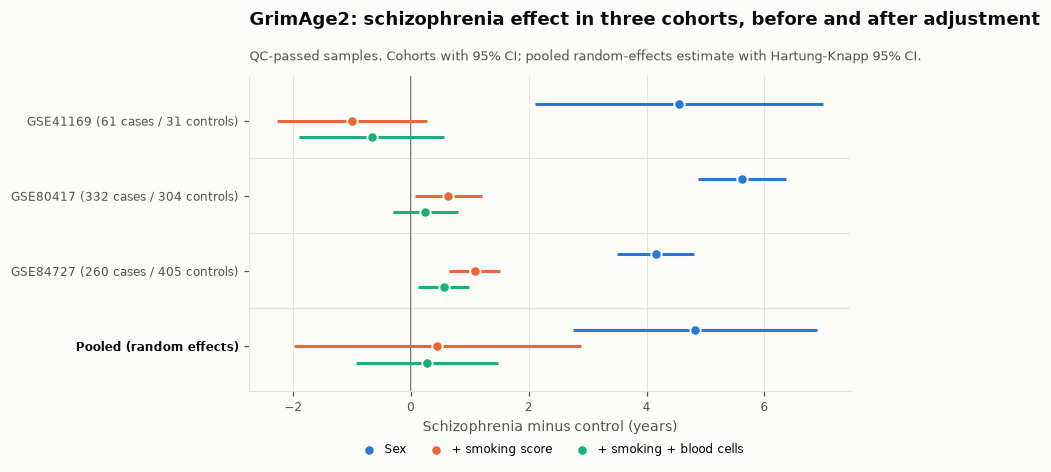

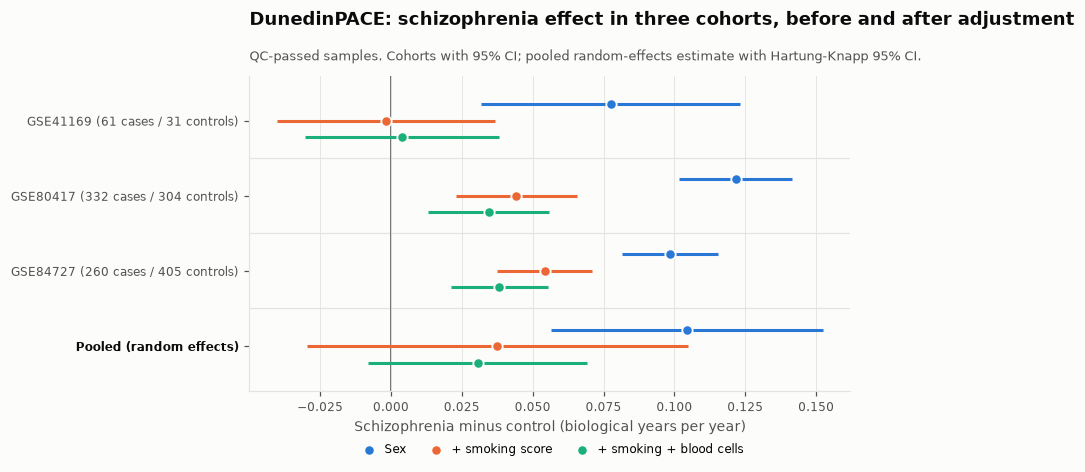

In [4]:
POOLED = "Pooled (random effects)"
for clock in FIGURE_CLOCKS:
    effects = {}
    for model, label in MODELS.items():
        g = per_cohort[(per_cohort["clock"] == clock) & (per_cohort["model"] == model)].set_index("cohort")
        tbl = g[["diff_adjusted", "se_adjusted"]].copy()
        tbl.index = [f"{c} ({g.loc[c, 'n_case']} cases / {g.loc[c, 'n_control']} controls)" for c in g.index]
        p = pooled.loc[(clock, model)]
        # The plot draws estimate +/- 1.96 SE, so give the pooled row the SE that reproduces its HKSJ interval
        tbl.loc[POOLED] = [p["random"], (p["hk_ci_high"] - p["random"]) / 1.96]
        effects[label] = tbl
    rows_bottom_to_top = [POOLED] + [r for r in reversed(tbl.index) if r != POOLED]

    fig = plot_adjustment_effect(
        effects, rows_bottom_to_top,
        title=f"{clock}: schizophrenia effect in three cohorts, before and after adjustment",
        subtitle="QC-passed samples. Cohorts with 95% CI; pooled random-effects estimate with Hartung-Knapp 95% CI.",
        xlabel=f"Schizophrenia minus control ({UNITS.get(clock, 'years')})",
        highlight={POOLED},
    )
    fig.savefig(out / f"fig_pooled_{clock}.png")
    plt.show()